# House Price Prediction Using Machine Learning

## Project Objective

The objective of this project is to analyse housing data and develop a machine learning model that predicts house sale prices based on property characteristics such as living area, number of bedrooms, overall quality, neighbourhood, construction year, and garage capacity.

The project includes data cleaning, exploratory data analysis, feature engineering, model training, model comparison, price prediction, and buyer recommendations.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset

In [2]:
# Load the dataset
df = pd.read_csv("Data/data.csv")

# Display the first 5 rows
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Understand the Dataset

In [3]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
df.info()

Dataset shape: (1460, 81)

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

## 4. Check Data Quality and Missing Values

In [4]:
# Check missing values in each column
missing_values = df.isnull().sum()

missing_report = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Total missing values:", df.isnull().sum().sum())
print("\nColumns with missing values:")
print(missing_report)

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate house IDs
print("Duplicate IDs:", df["Id"].duplicated().sum())

# Check missing sale prices
print("Missing SalePrice:", df["SalePrice"].isnull().sum())

# Check invalid sale prices
print("SalePrice less than or equal to zero:",
      (df["SalePrice"] <= 0).sum())

Total missing values: 7829

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0
Missing SalePrice: 0
SalePrice less than or equal to zero: 0


### 4.1 Understand Missing Values

In [5]:
# Check the meaning of missing values in important columns

columns_to_check = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageYrBlt",
    "BsmtQual",
    "BsmtCond",
    "LotFrontage",
    "MasVnrArea",
    "Electrical"
]

for column in columns_to_check:
    print(
        f"{column}: {df[column].isnull().sum()} missing values"
    )

PoolQC: 1453 missing values
MiscFeature: 1406 missing values
Alley: 1369 missing values
Fence: 1179 missing values
FireplaceQu: 690 missing values
GarageType: 81 missing values
GarageYrBlt: 81 missing values
BsmtQual: 37 missing values
BsmtCond: 37 missing values
LotFrontage: 259 missing values
MasVnrArea: 8 missing values
Electrical: 1 missing values


## 5. Data Cleaning and Missing-Value Treatment

In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Columns where missing values mean the feature is absent
absent_columns = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtFinType2",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtCond",
    "BsmtQual"
]

# Fill missing categorical values with "None"
for column in absent_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna("None")

# Garage year is missing when a garage is absent
df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(0)

# Missing masonry veneer area means no recorded veneer area
df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0)

# Missing masonry veneer type
df_clean["MasVnrType"] = df_clean["MasVnrType"].fillna("None")

# Lot frontage: fill with the median within each neighbourhood
df_clean["LotFrontage"] = df_clean.groupby(
    "Neighborhood"
)["LotFrontage"].transform(
    lambda values: values.fillna(values.median())
)

# Fill any remaining LotFrontage values with the overall median
df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(
    df_clean["LotFrontage"].median()
)

# Fill the one missing Electrical value with the most frequent category
df_clean["Electrical"] = df_clean["Electrical"].fillna(
    df_clean["Electrical"].mode()[0]
)

# Verify the cleaning
print("Missing values before cleaning:", df.isnull().sum().sum())
print("Missing values after cleaning:", df_clean.isnull().sum().sum())
print("Cleaned dataset shape:", df_clean.shape)

Missing values before cleaning: 7829
Missing values after cleaning: 0
Cleaned dataset shape: (1460, 81)


## 6. Exploratory Data Analysis (EDA)

SalePrice Summary Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

SalePrice Skewness: 1.8828757597682129


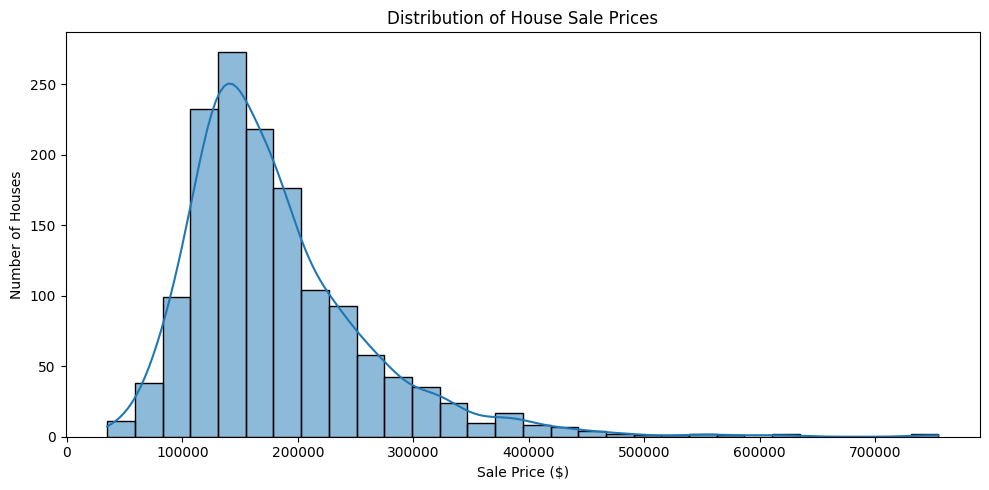

In [7]:
# Summary statistics of house prices
print("SalePrice Summary Statistics:")
display(df_clean["SalePrice"].describe())

# Calculate skewness
print("SalePrice Skewness:", df_clean["SalePrice"].skew())

# Plot the distribution of house prices
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["SalePrice"], bins=30, kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()

### 6.1 Correlation Analysis

Top 15 features positively correlated with SalePrice:


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
MasVnrArea      0.472614
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.349876
WoodDeckSF      0.324413
Name: SalePrice, dtype: float64


Top 10 negative correlations:


KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
MSSubClass      -0.084284
OverallCond     -0.077856
YrSold          -0.028923
LowQualFinSF    -0.025606
Id              -0.021917
MiscVal         -0.021190
BsmtHalfBath    -0.016844
BsmtFinSF2      -0.011378
Name: SalePrice, dtype: float64

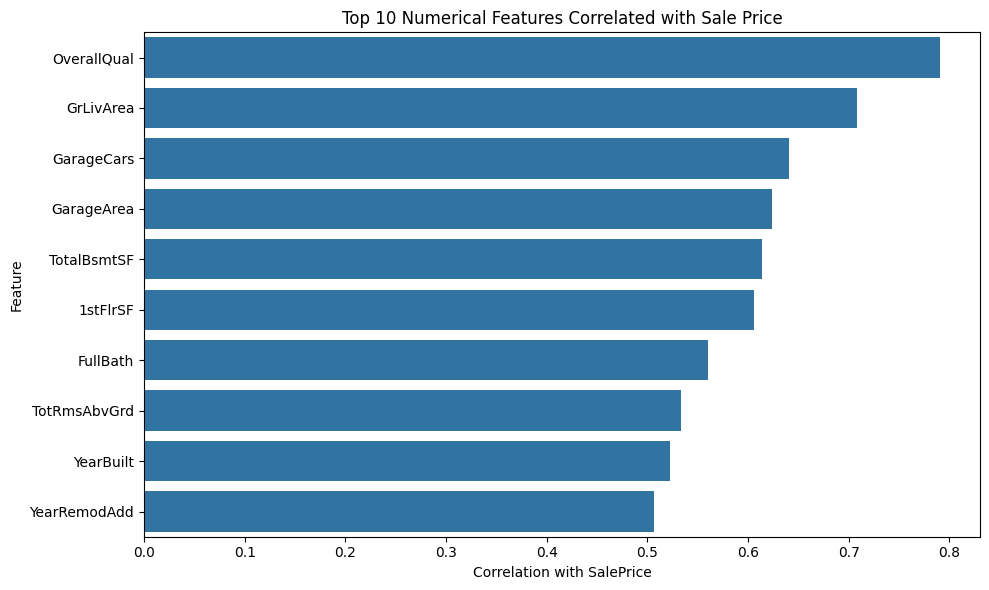

In [8]:
# Select numerical columns
numeric_df = df_clean.select_dtypes(include="number")

# Calculate correlation with SalePrice
price_correlation = numeric_df.corr()["SalePrice"].sort_values(
    ascending=False
)

print("Top 15 features positively correlated with SalePrice:")
display(price_correlation.head(16))

print("\nTop 10 negative correlations:")
display(price_correlation.sort_values().head(10))

# Plot the top 10 positive correlations, excluding SalePrice itself
top_features = price_correlation.drop("SalePrice").head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title("Top 10 Numerical Features Correlated with Sale Price")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 6.2 Overall Quality and Sale Price

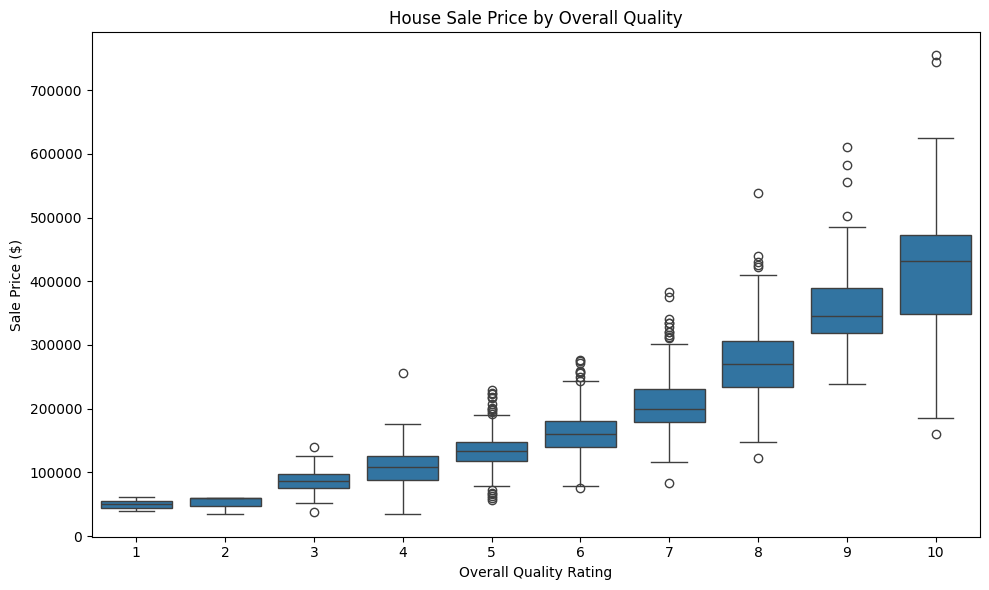

In [9]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="OverallQual",
    y="SalePrice"
)

plt.title("House Sale Price by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.show()

## 7. Feature Engineering

In [10]:
# Create a separate dataset for modelling
df_model = df_clean.copy()

# 1. Total house area
df_model["TotalHouseArea"] = (
    df_model["TotalBsmtSF"]
    + df_model["1stFlrSF"]
    + df_model["2ndFlrSF"]
)

# 2. House age at the time of sale
df_model["HouseAge"] = (
    df_model["YrSold"] - df_model["YearBuilt"]
).clip(lower=0)

# 3. Years since the last remodel at the time of sale
df_model["YearsSinceRemodel"] = (
    df_model["YrSold"] - df_model["YearRemodAdd"]
).clip(lower=0)

# 4. Total bathroom equivalents
df_model["TotalBathrooms"] = (
    df_model["FullBath"]
    + 0.5 * df_model["HalfBath"]
    + df_model["BsmtFullBath"]
    + 0.5 * df_model["BsmtHalfBath"]
)

# Display the new features
display(
    df_model[
        [
            "TotalHouseArea",
            "HouseAge",
            "YearsSinceRemodel",
            "TotalBathrooms",
            "SalePrice"
        ]
    ].head()
)

print("\nOriginal dataset shape:", df_clean.shape)
print("Modelling dataset shape:", df_model.shape)

,TotalHouseArea,HouseAge,YearsSinceRemodel,TotalBathrooms,SalePrice
0,2566,5,5,3.5,208500
1,2524,31,31,2.5,181500
2,2706,7,6,3.5,223500
3,2473,91,36,2.0,140000
4,3343,8,8,3.5,250000



Original dataset shape: (1460, 81)
Modelling dataset shape: (1460, 85)


## 8. Prepare Features and Split the Data

In [11]:
# Separate input features and target variable
X = df_model.drop(columns=["SalePrice", "Id"])
y = df_model["SalePrice"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset information
print("Total input features:", X.shape[1])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target rows:", y_train.shape[0])
print("Testing target rows:", y_test.shape[0])

Total input features: 83
Numerical features: 40
Categorical features: 43

Training rows: 1168
Testing rows: 292

Training target rows: 1168
Testing target rows: 292


## 9. Preprocessing Pipeline

In [12]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))

Preprocessing pipeline created successfully!
Numerical columns: 40
Categorical columns: 43


## 10. Model 1 — Random Forest Regressor

In [13]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

# Create the complete model pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [14]:
# Make predictions on the test dataset
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_r2 = r2_score(y_test, rf_predictions)

rf_mae = mean_absolute_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

# Display results
print("Random Forest Model Evaluation")
print("-" * 35)
print(f"R² Score: {rf_r2:.4f}")
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")

Random Forest Model Evaluation
-----------------------------------
R² Score: 0.8865
MAE: $17,589.81
RMSE: $29,504.26


## 11. Model 2 — Gradient Boosting Regressor

In [15]:
# Create the Gradient Boosting pipeline
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [16]:
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [17]:
# Predict house prices on the test dataset
gb_predictions = gb_model.predict(X_test)

# Calculate evaluation metrics
gb_r2 = r2_score(y_test, gb_predictions)
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))

# Display results
print("Gradient Boosting Model Evaluation")
print("-" * 40)
print(f"R² Score: {gb_r2:.4f} ({gb_r2 * 100:.2f}%)")
print(f"MAE: ${gb_mae:,.2f}")
print(f"RMSE: ${gb_rmse:,.2f}")

# Compare with Random Forest
print("\nModel Comparison")
print("-" * 40)
print(f"Random Forest R²: {rf_r2 * 100:.2f}%")
print(f"Gradient Boosting R²: {gb_r2 * 100:.2f}%")

Gradient Boosting Model Evaluation
----------------------------------------
R² Score: 0.9054 (90.54%)
MAE: $16,066.79
RMSE: $26,933.89

Model Comparison
----------------------------------------
Random Forest R²: 88.65%
Gradient Boosting R²: 90.54%


## 12. Cross-Validation

In [18]:
# Evaluate Gradient Boosting using 5-fold cross-validation
cv_scores = cross_val_score(
    gb_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Gradient Boosting - 5-Fold Cross-Validation")
print("-" * 45)

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f} ({score * 100:.2f}%)")

print(f"\nMean CV R²: {cv_scores.mean():.4f} ({cv_scores.mean() * 100:.2f}%)")
print(f"Standard deviation: {cv_scores.std():.4f}")

Gradient Boosting - 5-Fold Cross-Validation
---------------------------------------------
Fold 1: 0.8958 (89.58%)
Fold 2: 0.7989 (79.89%)
Fold 3: 0.8602 (86.02%)
Fold 4: 0.8780 (87.80%)
Fold 5: 0.8869 (88.69%)

Mean CV R²: 0.8640 (86.40%)
Standard deviation: 0.0346


## 13. Hyperparameter Tuning

In [19]:
from sklearn.model_selection import GridSearchCV

# Parameter combinations to test
param_grid = {
    "regressor__n_estimators": [200, 300, 400],
    "regressor__learning_rate": [0.03, 0.05, 0.08],
    "regressor__max_depth": [2, 3],
    "regressor__min_samples_leaf": [2, 5]
}

# Search for the best combination using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print(
    f"\nBest mean cross-validation R²: "
    f"{grid_search.best_score_:.4f} "
    f"({grid_search.best_score_ * 100:.2f}%)"
)

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best parameters:
{'regressor__learning_rate': 0.08, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 400}

Best mean cross-validation R²: 0.8718 (87.18%)


## 14. Final Tuned Model Evaluation

In [20]:
# Get the best tuned model
best_gb_model = grid_search.best_estimator_

# Predict on the test dataset
tuned_predictions = best_gb_model.predict(X_test)

# Calculate evaluation metrics
tuned_r2 = r2_score(y_test, tuned_predictions)
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

print("Tuned Gradient Boosting Evaluation")
print("-" * 40)
print(f"R² Score: {tuned_r2:.4f} ({tuned_r2 * 100:.2f}%)")
print(f"MAE: ${tuned_mae:,.2f}")
print(f"RMSE: ${tuned_rmse:,.2f}")

print("\nComparison")
print("-" * 40)
print(f"Random Forest R²: {rf_r2 * 100:.2f}%")
print(f"Original Gradient Boosting R²: {gb_r2 * 100:.2f}%")
print(f"Tuned Gradient Boosting R²: {tuned_r2 * 100:.2f}%")

Tuned Gradient Boosting Evaluation
----------------------------------------
R² Score: 0.9137 (91.37%)
MAE: $15,449.79
RMSE: $25,735.02

Comparison
----------------------------------------
Random Forest R²: 88.65%
Original Gradient Boosting R²: 90.54%
Tuned Gradient Boosting R²: 91.37%


## 15. Actual vs. Predicted Prices

,Actual Price,Predicted Price,Absolute Error
892,154500,142510.15,11989.85
1105,325000,338409.80,13409.80
413,115000,112209.34,2790.66
522,159000,157396.74,1603.26
1036,315500,345147.97,29647.97
614,75500,70521.84,4978.16
218,311500,219303.79,92196.21
1160,146000,147921.51,1921.51
649,84500,70704.13,13795.87
887,135500,140993.43,5493.43


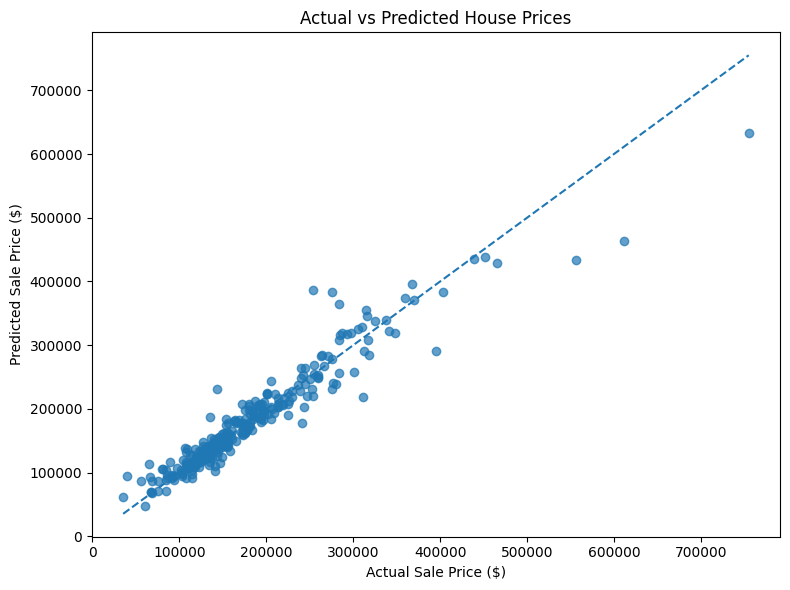

In [21]:
# Compare actual and predicted house prices
comparison_df = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": tuned_predictions
})

comparison_df["Absolute Error"] = (
    comparison_df["Actual Price"]
    - comparison_df["Predicted Price"]
).abs()

display(comparison_df.head(10).round(2))

# Plot actual vs predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison_df["Actual Price"],
    comparison_df["Predicted Price"],
    alpha=0.7
)

# Reference line for perfect predictions
min_price = min(
    comparison_df["Actual Price"].min(),
    comparison_df["Predicted Price"].min()
)
max_price = max(
    comparison_df["Actual Price"].max(),
    comparison_df["Predicted Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.tight_layout()
plt.show()

## 16. Feature Importance

Top 15 Most Important Features:


,Importance
num__TotalHouseArea,0.430684
num__OverallQual,0.288920
num__2ndFlrSF,0.026409
num__TotalBathrooms,0.024616
num__GarageCars,0.024088
num__HouseAge,0.019926
cat__BsmtQual_Ex,0.017056
num__LotArea,0.013503
num__YearBuilt,0.013491
num__BsmtFinSF1,0.012383


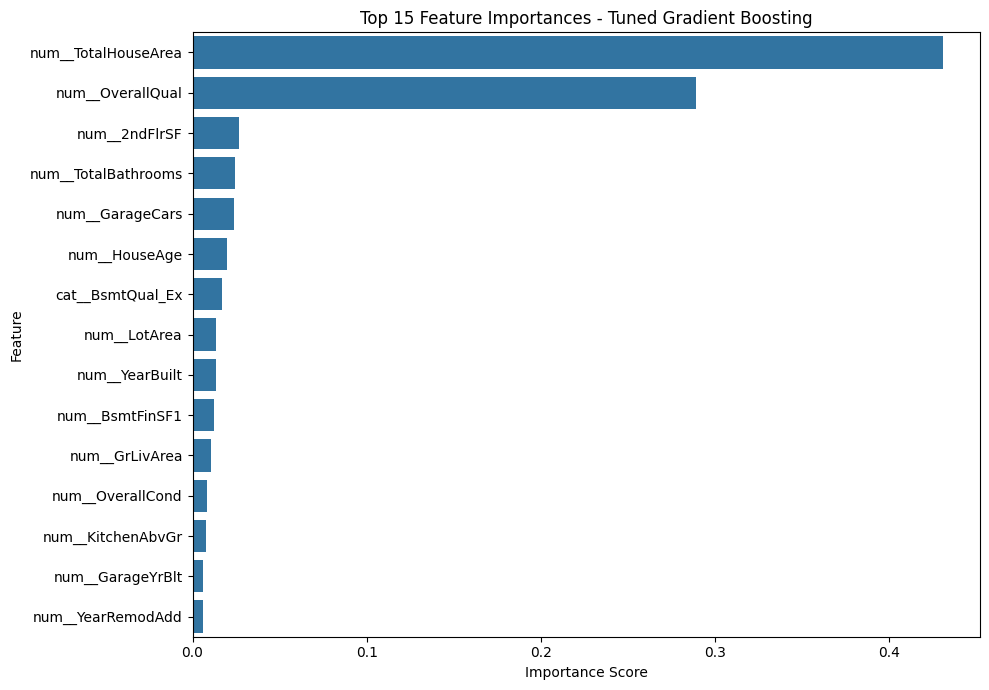

In [22]:
# Extract the fitted preprocessing and model steps
fitted_preprocessor = best_gb_model.named_steps["preprocessor"]
fitted_regressor = best_gb_model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance scores
feature_importance = pd.Series(
    fitted_regressor.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# Display the top 15 features
print("Top 15 Most Important Features:")
display(feature_importance.head(15).to_frame("Importance"))

# Plot the top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    x=feature_importance.head(15).values,
    y=feature_importance.head(15).index
)

plt.title("Top 15 Feature Importances - Tuned Gradient Boosting")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 17. Prediction Sensitivity Checks

In [23]:
print("best_gb_model:", "best_gb_model" in globals())
print("gb_model:", "gb_model" in globals())
print("X_train:", "X_train" in globals())
print("df_model:", "df_model" in globals())

best_gb_model: True
gb_model: True
X_train: True
df_model: True


In [24]:
test_areas = [1200, 1800, 2600]

print("Living Area Prediction Test")
print("-" * 45)

for area in test_areas:
    # Start with a typical house from the training data
    house = X_train.median(numeric_only=True).to_frame().T

    # Fill categorical features with their most common values
    for column in X_train.select_dtypes(exclude="number").columns:
        house[column] = X_train[column].mode()[0]

    # Set fixed house details
    house["Neighborhood"] = "CollgCr"
    house["OverallQual"] = 7
    house["GrLivArea"] = area
    house["BedroomAbvGr"] = 3
    house["FullBath"] = 2
    house["GarageCars"] = 2
    house["YearBuilt"] = 2005

    # Update floor areas to match the selected living area
    original_area = float(
        house["1stFlrSF"].iloc[0] +
        house["2ndFlrSF"].iloc[0]
    )

    share = (
        float(house["2ndFlrSF"].iloc[0]) / original_area
        if original_area > 0 else 0
    )

    house["2ndFlrSF"] = round(area * share)
    house["1stFlrSF"] = area - house["2ndFlrSF"].iloc[0]

    house["TotalHouseArea"] = (
        house["TotalBsmtSF"] +
        house["1stFlrSF"] +
        house["2ndFlrSF"]
    )

    sale_year = int(house["YrSold"].iloc[0])
    house["HouseAge"] = max(0, sale_year - 2005)
    house["YearsSinceRemodel"] = max(
        0, sale_year - int(house["YearRemodAdd"].iloc[0])
    )

    house["TotalBathrooms"] = (
        house["FullBath"] +
        0.5 * house["HalfBath"] +
        house["BsmtFullBath"] +
        0.5 * house["BsmtHalfBath"]
    )

    # Predict with the tuned model
    price = best_gb_model.predict(house)[0]
    print(f"{area:,} sq ft -> ${price:,.2f}")

Living Area Prediction Test
---------------------------------------------
1,200 sq ft -> $162,230.62
1,800 sq ft -> $185,136.47
2,600 sq ft -> $224,438.98


In [25]:
print("neighborhood_widget exists:", "neighborhood_widget" in globals())
print("quality_widget exists:", "quality_widget" in globals())
print("area_widget exists:", "area_widget" in globals())
print("prediction_model exists:", "prediction_model" in globals())

neighborhood_widget exists: False
quality_widget exists: False
area_widget exists: False
prediction_model exists: False


In [26]:
# Test different overall quality ratings
test_qualities = [4, 7, 10]

print("Overall Quality Prediction Test")
print("-" * 45)

for quality in test_qualities:
    house = X_train.median(numeric_only=True).to_frame().T

    for column in X_train.select_dtypes(
        exclude="number"
    ).columns:
        house[column] = X_train[column].mode()[0]

    house["Neighborhood"] = "CollgCr"
    house["OverallQual"] = quality
    house["GrLivArea"] = 1800
    house["BedroomAbvGr"] = 3
    house["FullBath"] = 2
    house["GarageCars"] = 2
    house["YearBuilt"] = 2005

    original_area = float(
        house["1stFlrSF"].iloc[0]
        + house["2ndFlrSF"].iloc[0]
    )

    share = (
        float(house["2ndFlrSF"].iloc[0]) / original_area
        if original_area > 0 else 0
    )

    house["2ndFlrSF"] = round(1800 * share)
    house["1stFlrSF"] = 1800 - house["2ndFlrSF"].iloc[0]

    house["TotalHouseArea"] = (
        house["TotalBsmtSF"]
        + house["1stFlrSF"]
        + house["2ndFlrSF"]
    )

    sale_year = int(house["YrSold"].iloc[0])
    house["HouseAge"] = max(0, sale_year - 2005)
    house["YearsSinceRemodel"] = max(
        0, sale_year - int(house["YearRemodAdd"].iloc[0])
    )

    house["TotalBathrooms"] = (
        house["FullBath"]
        + 0.5 * house["HalfBath"]
        + house["BsmtFullBath"]
        + 0.5 * house["BsmtHalfBath"]
    )

    price = best_gb_model.predict(house)[0]
    print(f"Quality {quality}/10 -> ${price:,.2f}")
    

Overall Quality Prediction Test
---------------------------------------------
Quality 4/10 -> $165,077.30
Quality 7/10 -> $185,136.47
Quality 10/10 -> $195,153.61


In [27]:
test_bedrooms = [2, 3, 5]

print("Bedroom Count Prediction Test")
print("-" * 45)

for bedrooms in test_bedrooms:
    house = X_train.median(numeric_only=True).to_frame().T

    for column in X_train.select_dtypes(exclude="number").columns:
        house[column] = X_train[column].mode()[0]

    house["Neighborhood"] = "CollgCr"
    house["OverallQual"] = 7
    house["GrLivArea"] = 1800
    house["BedroomAbvGr"] = bedrooms
    house["FullBath"] = 2
    house["GarageCars"] = 2
    house["YearBuilt"] = 2005

    original_area = float(
        house["1stFlrSF"].iloc[0] + house["2ndFlrSF"].iloc[0]
    )
    share = (
        float(house["2ndFlrSF"].iloc[0]) / original_area
        if original_area > 0 else 0
    )

    house["2ndFlrSF"] = round(1800 * share)
    house["1stFlrSF"] = 1800 - house["2ndFlrSF"].iloc[0]

    house["TotalHouseArea"] = (
        house["TotalBsmtSF"]
        + house["1stFlrSF"]
        + house["2ndFlrSF"]
    )

    sale_year = int(house["YrSold"].iloc[0])
    house["HouseAge"] = max(0, sale_year - 2005)
    house["YearsSinceRemodel"] = max(
        0, sale_year - int(house["YearRemodAdd"].iloc[0])
    )
    house["TotalBathrooms"] = (
        house["FullBath"]
        + 0.5 * house["HalfBath"]
        + house["BsmtFullBath"]
        + 0.5 * house["BsmtHalfBath"]
    )

    price = best_gb_model.predict(house)[0]
    print(f"{bedrooms} bedrooms -> ${price:,.2f}")

Bedroom Count Prediction Test
---------------------------------------------
2 bedrooms -> $185,136.47
3 bedrooms -> $185,136.47
5 bedrooms -> $185,136.47


### 17.1 Bedroom Feature Diagnostic

In [28]:
print("Bedroom values in the training data:")
print(X_train["BedroomAbvGr"].value_counts().sort_index())

print("\nBedroom feature importance:")
bedroom_importance = feature_importance[
    feature_importance.index.str.contains("BedroomAbvGr")
]
print(bedroom_importance)

Bedroom values in the training data:
BedroomAbvGr
0      4
1     34
2    280
3    649
4    179
5     15
6      6
8      1
Name: count, dtype: int64

Bedroom feature importance:
num__BedroomAbvGr    0.000672
dtype: float64


In [29]:
test_garages = [0, 1, 3]

print("Garage Capacity Prediction Test")
print("-" * 45)

for garage_spaces in test_garages:
    house = X_train.median(numeric_only=True).to_frame().T

    for column in X_train.select_dtypes(exclude="number").columns:
        house[column] = X_train[column].mode()[0]

    house["Neighborhood"] = "CollgCr"
    house["OverallQual"] = 7
    house["GrLivArea"] = 1800
    house["BedroomAbvGr"] = 3
    house["FullBath"] = 2
    house["GarageCars"] = garage_spaces
    house["YearBuilt"] = 2005

    original_area = float(
        house["1stFlrSF"].iloc[0] + house["2ndFlrSF"].iloc[0]
    )
    share = (
        float(house["2ndFlrSF"].iloc[0]) / original_area
        if original_area > 0 else 0
    )

    house["2ndFlrSF"] = round(1800 * share)
    house["1stFlrSF"] = 1800 - house["2ndFlrSF"].iloc[0]

    house["TotalHouseArea"] = (
        house["TotalBsmtSF"]
        + house["1stFlrSF"]
        + house["2ndFlrSF"]
    )

    sale_year = int(house["YrSold"].iloc[0])
    house["HouseAge"] = max(0, sale_year - 2005)
    house["YearsSinceRemodel"] = max(
        0, sale_year - int(house["YearRemodAdd"].iloc[0])
    )
    house["TotalBathrooms"] = (
        house["FullBath"]
        + 0.5 * house["HalfBath"]
        + house["BsmtFullBath"]
        + 0.5 * house["BsmtHalfBath"]
    )

    price = best_gb_model.predict(house)[0]
    print(f"{garage_spaces} garage spaces -> ${price:,.2f}")

Garage Capacity Prediction Test
---------------------------------------------
0 garage spaces -> $181,027.68
1 garage spaces -> $181,027.68
3 garage spaces -> $186,396.51


## 18. Final Model Performance Summary

In [30]:
print("FINAL MODEL PERFORMANCE")
print("-" * 40)
print(f"R² Score: {r2_score(y_test, tuned_predictions):.4f}")
print(f"R² Percentage: {r2_score(y_test, tuned_predictions) * 100:.2f}%")
print(f"MAE: ${mean_absolute_error(y_test, tuned_predictions):,.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, tuned_predictions)):,.2f}")
print(f"Mean Cross-Validation R²: {grid_search.best_score_ * 100:.2f}%")

FINAL MODEL PERFORMANCE
----------------------------------------
R² Score: 0.9137
R² Percentage: 91.37%
MAE: $15,449.79
RMSE: $25,735.02
Mean Cross-Validation R²: 87.18%


## 19. Buyer Recommendation System

In [31]:
print("BUYER RECOMMENDATION SYSTEM")
print("-" * 40)

print("\nAvailable neighborhoods:")
print(sorted(df_model["Neighborhood"].dropna().unique()))

print("\nHouse price range in the dataset:")
print(f"Minimum: ${df_model['SalePrice'].min():,.0f}")
print(f"Median:  ${df_model['SalePrice'].median():,.0f}")
print(f"Maximum: ${df_model['SalePrice'].max():,.0f}")

print("\nAvailable house quality ratings:")
print(sorted(df_model["OverallQual"].dropna().unique()))

BUYER RECOMMENDATION SYSTEM
----------------------------------------

Available neighborhoods:
['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']

House price range in the dataset:
Minimum: $34,900
Median:  $163,000
Maximum: $755,000

Available house quality ratings:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


### 19.1 Recommendation Function

In [32]:
def recommend_houses(budget, neighborhood="Any", min_quality=5, top_n=10):

    # Filter houses within the buyer's budget
    recommendations = df_model[
        (df_model["SalePrice"] <= budget) &
        (df_model["OverallQual"] >= min_quality)
    ].copy()

    # Filter by neighborhood if one is selected
    if neighborhood != "Any":
        recommendations = recommendations[
            recommendations["Neighborhood"] == neighborhood
        ]

    # Select useful details for buyers
    columns = [
        "Id",
        "Neighborhood",
        "SalePrice",
        "OverallQual",
        "GrLivArea",
        "BedroomAbvGr",
        "FullBath",
        "GarageCars",
        "YearBuilt"
    ]

    # Sort by price, lowest first
    recommendations = recommendations[columns].sort_values(
        by="SalePrice"
    )

    # Display the best matching results
    if recommendations.empty:
        print("No houses match your selected requirements.")
        print("Try increasing your budget or lowering minimum quality.")
    else:
        print("HOUSE RECOMMENDATIONS")
        print("-" * 50)
        print(f"Maximum budget: ${budget:,.0f}")
        print(f"Neighborhood: {neighborhood}")
        print(f"Minimum quality: {min_quality}/10")
        print(f"Matching houses: {len(recommendations)}")
        print()

        display(recommendations.head(top_n).style.format({
            "SalePrice": "${:,.0f}",
            "GrLivArea": "{:,.0f}"
        }))

    return recommendations.head(top_n)

In [33]:
buyer_results = recommend_houses(
    budget=200000,
    neighborhood="CollgCr",
    min_quality=6,
    top_n=10
)

HOUSE RECOMMENDATIONS
--------------------------------------------------
Maximum budget: $200,000
Neighborhood: CollgCr
Minimum quality: 6/10
Matching houses: 50



,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,BedroomAbvGr,FullBath,GarageCars,YearBuilt
850,851,CollgCr,"$131,500",6,848,1,1,2,2003
1422,1423,CollgCr,"$136,500",6,848,1,1,2,2003
593,594,CollgCr,"$140,000",6,848,1,1,2,2003
690,691,CollgCr,"$141,000",6,848,1,1,2,2004
721,722,CollgCr,"$143,000",6,848,1,1,2,2004
1368,1369,CollgCr,"$144,000",6,848,1,1,2,2003
811,812,CollgCr,"$144,500",6,848,1,1,2,2004
856,857,CollgCr,"$147,000",6,"1,026",3,1,2,1978
203,204,CollgCr,"$149,000",6,848,1,1,2,2004
1441,1442,CollgCr,"$149,300",6,848,1,1,2,2004


## 20. Correlation Chart for the Report

Top 15 features positively correlated with SalePrice:


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
MasVnrArea      0.472614
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.349876
WoodDeckSF      0.324413
Name: SalePrice, dtype: float64


Top 10 negative correlations:


KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
MSSubClass      -0.084284
OverallCond     -0.077856
YrSold          -0.028923
LowQualFinSF    -0.025606
Id              -0.021917
MiscVal         -0.021190
BsmtHalfBath    -0.016844
BsmtFinSF2      -0.011378
Name: SalePrice, dtype: float64

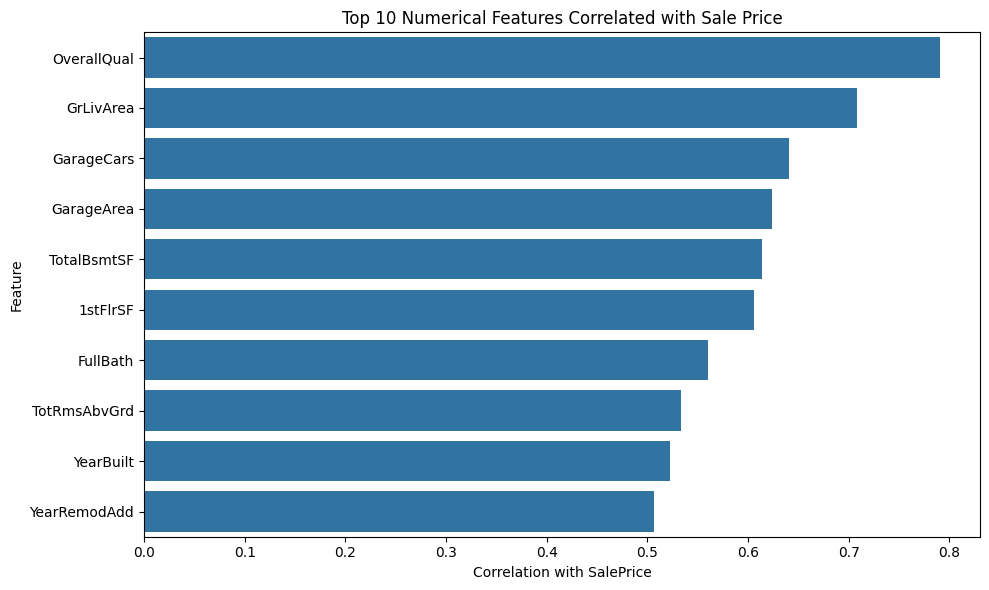

In [34]:
# Select numerical columns
numeric_df = df_clean.select_dtypes(include="number")

# Calculate correlation with SalePrice
price_correlation = numeric_df.corr()["SalePrice"].sort_values(
    ascending=False
)

print("Top 15 features positively correlated with SalePrice:")
display(price_correlation.head(16))

print("\nTop 10 negative correlations:")
display(price_correlation.sort_values().head(10))

# Plot the top 10 positive correlations, excluding SalePrice itself
top_features = price_correlation.drop("SalePrice").head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title("Top 10 Numerical Features Correlated with Sale Price")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

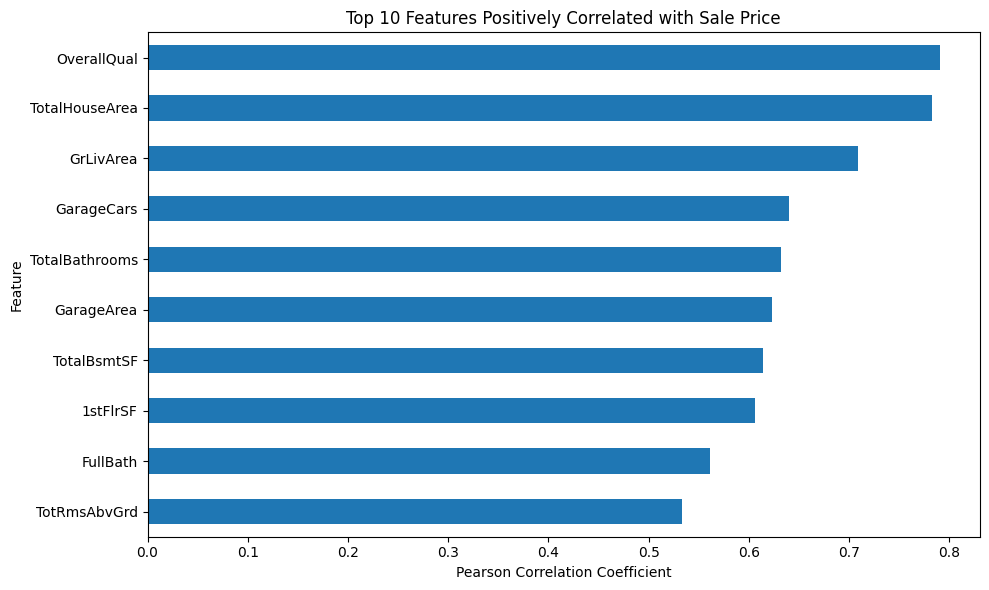

Correlation chart saved successfully.


In [35]:
# Select the 10 strongest numerical correlations with SalePrice
correlations = (
    df_model.select_dtypes(include="number")
    .corr(numeric_only=True)["SalePrice"]
    .drop("SalePrice")
)

top_10_corr = correlations.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_10_corr.sort_values().plot(kind="barh")

plt.title("Top 10 Features Positively Correlated with Sale Price")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "top10_price_correlations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Correlation chart saved successfully.")

## 21. Model Comparison Report

Three regression configurations are considered: Random Forest, the initial Gradient Boosting model, and the tuned Gradient Boosting model. The same train/test split is used so that their test-set metrics can be compared consistently.

- **R²** measures the proportion of target variation explained by the model on the test set.
- **MAE** is the average absolute difference between actual and predicted prices.
- **RMSE** gives larger errors more weight than MAE.
- Cross-validation provides an additional estimate of performance across training folds.

The tuned model is selected based on the observed test-set metrics, while the difference between test performance and cross-validation performance should be reported transparently. These values do not guarantee performance on another dataset or current housing markets.

In [36]:
# Final comparison table: metrics calculated from the models above
model_comparison_report = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting", "Tuned Gradient Boosting"],
    "Test R2": [rf_r2, gb_r2, tuned_r2],
    "Test MAE ($)": [rf_mae, gb_mae, tuned_mae],
    "Test RMSE ($)": [rf_rmse, gb_rmse, tuned_rmse]
})

display(model_comparison_report.style.format({
    "Test R2": "{:.4f}",
    "Test MAE ($)": "${:,.2f}",
    "Test RMSE ($)": "${:,.2f}"
}))

,Model,Test R2,Test MAE ($),Test RMSE ($)
0,Random Forest,0.8865,"$17,589.81","$29,504.26"
1,Gradient Boosting,0.9054,"$16,066.79","$26,933.89"
2,Tuned Gradient Boosting,0.9137,"$15,449.79","$25,735.02"


## 22. Data Analysis Report

The dataset contains 1,460 historical house sales and 81 original columns, including the target `SalePrice`. Data inspection found missing values in several columns but no duplicate rows. Missing values were treated according to their meaning: missing descriptions for absent features were represented as `None`, numerical values were imputed using appropriate values, and `LotFrontage` was imputed using neighbourhood medians with an overall-median fallback.

Exploratory analysis showed a right-skewed sale-price distribution. `OverallQual` and living-area features had strong positive correlations with sale price. Correlation is an association measure and does not establish causation. Feature engineering added total house area, house age at sale, years since remodelling, and total bathroom equivalents.

## 23. Challenges Faced and Techniques Used

1. **Missing values:** Some missing category values indicated that a property feature was absent, rather than unknown. These were handled separately from numerical missing values.
2. **Mixed feature types:** Numerical and categorical columns require different preprocessing. A `ColumnTransformer` applies median imputation and scaling to numeric columns, and most-frequent imputation and one-hot encoding to categorical columns.
3. **Avoiding leakage:** Preprocessing is inside the model pipeline, so its transformations are fitted on training data during model fitting and cross-validation.
4. **Feature engineering:** Derived features were checked and constrained to avoid negative ages and years since remodelling.
5. **Model tuning:** Grid search tested combinations of Gradient Boosting parameters with five-fold cross-validation. This is computationally more expensive than training a single model.
6. **Prediction uncertainty:** Some predictions can have substantial errors. Test metrics and cross-validation results are both included, and predictions are described as estimates.
7. **Historical dataset limitation:** The data represents sales in Ames, Iowa, primarily from 2006–2010. It should not be interpreted as a direct estimate of present-day market prices or transferred uncritically to other locations.

## 24. Buyer Recommendation System — Interpretation

The recommendation function filters historical dataset records by maximum budget, optional neighbourhood, and minimum overall quality, then sorts matching records by sale price. The returned rows are historical examples, **not current property listings**. Buyers should consider other factors such as property condition, location, taxes, maintenance costs, and current market information before making a real purchase decision.

## 25. Conclusion and Future Improvements

This project demonstrates a complete regression workflow: data inspection, cleaning, exploratory analysis, feature engineering, preprocessing, model comparison, cross-validation, hyperparameter tuning, feature interpretation, and buyer-oriented filtering. In the current run, the tuned Gradient Boosting model achieved a test R² of approximately 0.9137, MAE of about $15,449.79, RMSE of about $25,735.02, and mean grid-search cross-validation R² of approximately 0.8718. These are run-specific results; rerunning with different package versions or data changes may produce different values.

Future improvements could include a time-aware validation strategy, prediction intervals, more systematic treatment of outliers, external recent market data, and a web application for easier use.

## 26. Interactive House Price Prediction Interface

Use the controls below to enter a hypothetical house's details and click **Predict House Price**. Unspecified characteristics are filled using typical values from the training dataset, so the result is an estimate rather than a guaranteed sale price. The training data is historical (Ames, Iowa; 2006–2010).

In [37]:
import ipywidgets as widgets
from IPython.display import display, clear_output

prediction_model = best_gb_model

neighborhood = widgets.Dropdown(
    options=sorted(df_model["Neighborhood"].dropna().unique()),
    value="CollgCr",
    description="Location:",
    layout=widgets.Layout(width="450px")
)
quality = widgets.IntSlider(value=7, min=1, max=10, description="Quality:", layout=widgets.Layout(width="450px"))
area = widgets.IntSlider(value=1800, min=300, max=5000, step=100, description="Living Area:", layout=widgets.Layout(width="450px"))
bedrooms = widgets.IntSlider(value=3, min=1, max=8, description="Bedrooms:", layout=widgets.Layout(width="450px"))
bathrooms = widgets.IntSlider(value=2, min=1, max=5, description="Full Bathrooms:", layout=widgets.Layout(width="450px"))
garage = widgets.IntSlider(value=2, min=0, max=4, description="Garage Spaces:", layout=widgets.Layout(width="450px"))
year_built = widgets.IntSlider(value=2005, min=1872, max=2010, description="Year Built:", layout=widgets.Layout(width="450px"))
predict_button = widgets.Button(description="Predict House Price", button_style="success", icon="check", layout=widgets.Layout(width="250px", height="45px"))
output = widgets.Output()

def predict_house_price(_):
    with output:
        clear_output(wait=True)
        house = X_train.median(numeric_only=True).to_frame().T
        for col in X_train.select_dtypes(exclude="number").columns:
            house[col] = X_train[col].mode()[0]

        house["Neighborhood"] = neighborhood.value
        house["OverallQual"] = quality.value
        house["GrLivArea"] = area.value
        house["BedroomAbvGr"] = bedrooms.value
        house["FullBath"] = bathrooms.value
        house["GarageCars"] = garage.value
        house["YearBuilt"] = year_built.value

        original_area = float(house["1stFlrSF"].iloc[0] + house["2ndFlrSF"].iloc[0])
        share = float(house["2ndFlrSF"].iloc[0]) / original_area if original_area > 0 else 0
        house["2ndFlrSF"] = round(area.value * share)
        house["1stFlrSF"] = area.value - house["2ndFlrSF"].iloc[0]
        house["TotalHouseArea"] = house["TotalBsmtSF"] + house["1stFlrSF"] + house["2ndFlrSF"]

        sale_year = int(house["YrSold"].iloc[0])
        house["HouseAge"] = max(0, sale_year - year_built.value)
        house["YearsSinceRemodel"] = max(0, sale_year - int(house["YearRemodAdd"].iloc[0]))
        house["TotalBathrooms"] = (
            house["FullBath"] + 0.5 * house["HalfBath"]
            + house["BsmtFullBath"] + 0.5 * house["BsmtHalfBath"]
        )

        predicted_price = prediction_model.predict(house)[0]
        print("HOUSE PRICE PREDICTION")
        print("=" * 35)
        print(f"Neighborhood: {neighborhood.value}")
        print(f"Living area: {area.value:,} sq ft")
        print(f"Bedrooms: {bedrooms.value}")
        print(f"Full bathrooms: {bathrooms.value}")
        print(f"Overall quality: {quality.value}/10")
        print(f"Garage spaces: {garage.value}")
        print(f"Year built: {year_built.value}")
        print("-" * 35)
        print(f"Estimated historical sale price: ${predicted_price:,.2f}")
        print("This is a model estimate based on historical sales, not a current market quote.")

predict_button.on_click(predict_house_price)
display(widgets.HTML("<h2>House Price Prediction System</h2><p>Enter property details and click Predict.</p>"))
display(widgets.VBox([neighborhood, quality, area, bedrooms, bathrooms, garage, year_built, predict_button, output], layout=widgets.Layout(border="1px solid #cccccc", padding="20px", width="550px")))

HTML(value='<h2>House Price Prediction System</h2><p>Enter property details and click Predict.</p>')